# 01 — EDA: Telco Customer Churn

Goal: understand the data, find quality issues, spot patterns for modeling. No modeling here.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
SEED = 42
np.random.seed(SEED)

sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 50)

DATA_PATH = Path('../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv')
FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
PALETTE = {'No': '#4C72B0', 'Yes': '#C44E52'}

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=150, bbox_inches='tight')

## 1. First look & data audit

In [2]:
df = pd.read_csv(DATA_PATH)
print('shape:', df.shape)
df.head()

shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
display(df.describe().round(2))
display(df.describe(exclude='number').T)

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


**Column groups:** ID (`customerID`), demographics, services, account/billing, target (`Churn`).

`SeniorCitizen` is 0/1 but categorical.

In [5]:
audit = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_missing': df.isna().sum(),
    'pct_missing': (df.isna().mean() * 100).round(2),
    'n_unique': df.nunique(),
})
display(audit)

print('duplicate rows:', df.duplicated().sum())
print('customerID unique:', df['customerID'].is_unique)

,dtype,n_missing,pct_missing,n_unique
customerID,str,0,0.0,7043
gender,str,0,0.0,2
SeniorCitizen,int64,0,0.0,2
Partner,str,0,0.0,2
Dependents,str,0,0.0,2
tenure,int64,0,0.0,73
PhoneService,str,0,0.0,2
MultipleLines,str,0,0.0,3
InternetService,str,0,0.0,3
OnlineSecurity,str,0,0.0,3


duplicate rows: 0
customerID unique: True


**Audit:** no `NaN`, no duplicates. But `TotalCharges` is read as text, so it hides missing values.

## 2. `TotalCharges` issue

In [6]:
tc_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce')
bad = df[tc_numeric.isna()]

print('rows with non-numeric TotalCharges:', len(bad))
print('raw values:', [repr(v) for v in bad['TotalCharges'].unique()])
display(bad[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
print('tenure values in these rows:', bad['tenure'].unique())
print('Churn values in these rows:', bad['Churn'].unique())

rows with non-numeric TotalCharges: 11
raw values: ["' '"]


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


tenure values in these rows: [0]
Churn values in these rows: <StringArray>
['No']
Length: 1, dtype: str


**Finding:** 11 rows have a blank `TotalCharges`. All have `tenure = 0` and `Churn = No` (new customers).

**Decision:** fill with `0`. Not mean/median (wrong meaning), not drop. It is a fixed rule, so no leakage. Repeat it in `src/preprocess.py`.

In [7]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
assert df.loc[df['TotalCharges'].isna(), 'tenure'].eq(0).all()
df.loc[df['TotalCharges'].isna(), 'TotalCharges'] = 0.0
assert df['TotalCharges'].isna().sum() == 0
print(df['TotalCharges'].dtype, '| missing:', df['TotalCharges'].isna().sum())

float64 | missing: 0


In [8]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in df.columns if c not in num_cols + ['customerID', 'Churn']]

print(f'numeric: {len(num_cols)}  |  categorical: {len(cat_cols)}')
for c in cat_cols:
    print(f'{c:18s}', sorted(df[c].unique().tolist()))

numeric: 3  |  categorical: 16
gender             ['Female', 'Male']
SeniorCitizen      [0, 1]
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']


**Note:** `No internet service` / `No phone service` duplicate the `No` info of another column. `OneHotEncoder` handles it; expect some collinearity.

## 3. Target: `Churn`

In [9]:
df['Churn_flag'] = df['Churn'].map({'No': 0, 'Yes': 1})
assert df['Churn_flag'].notna().all()

counts = df['Churn'].value_counts()
pct = df['Churn'].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({'count': counts, 'percent': pct}))

baseline_acc = counts.max() / counts.sum()
print(f'majority-class accuracy (baseline): {baseline_acc:.3f}')

,count,percent
Churn,,
No,5174,73.5
Yes,1869,26.5


majority-class accuracy (baseline): 0.735


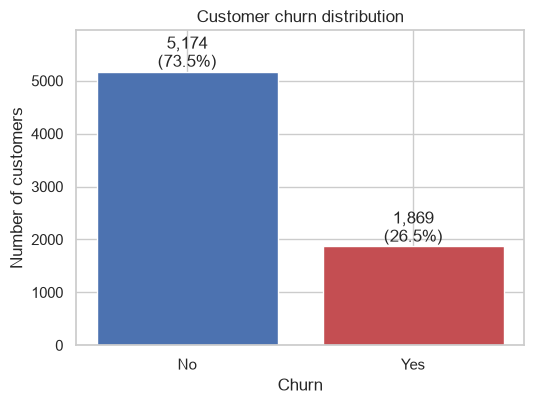

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
bars = ax.bar(counts.index, counts.values,
              color=[PALETTE[k] for k in counts.index])
ax.bar_label(bars, labels=[f'{n:,}\n({p}%)' for n, p in zip(counts.values, pct.loc[counts.index])])
ax.set_title('Customer churn distribution')
ax.set_xlabel('Churn')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, counts.max() * 1.15)
save_fig('01_churn_distribution')
plt.show()

**Result:** 26.5% churn, so the data is imbalanced. "Always No" gets ~73.5% accuracy. Use recall/F1/PR-AUC and `stratify=y`.

## 4. Categorical features vs churn

In [11]:
overall_rate = df['Churn_flag'].mean() * 100

def churn_rate(col):
    g = df.groupby(col, observed=True)['Churn_flag'].agg(rate='mean', n='size')
    g['rate'] = g['rate'] * 100
    return g.sort_values('rate', ascending=False)

display(churn_rate('Contract').round(1))

,rate,n
Contract,,
Month-to-month,42.7,3875
One year,11.3,1473
Two year,2.8,1695


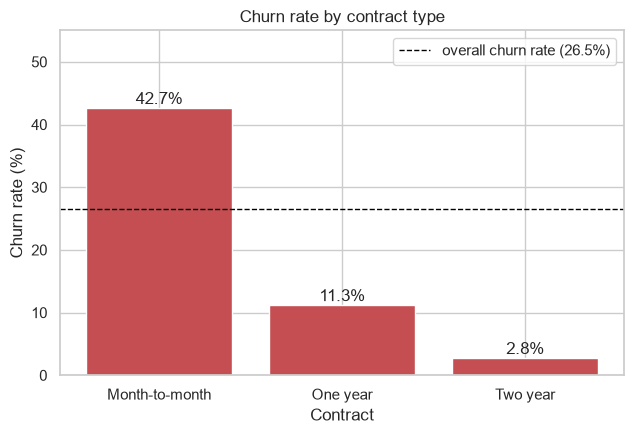

In [12]:
g = churn_rate('Contract')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
bars = ax.bar(g.index.astype(str), g['rate'], color='#C44E52')
ax.bar_label(bars, fmt='%.1f%%')
ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1,
           label=f'overall churn rate ({overall_rate:.1f}%)')
ax.set_title('Churn rate by contract type')
ax.set_xlabel('Contract')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 55)
ax.legend()
save_fig('02_churn_by_contract')
plt.show()

**Result:** month-to-month churns 42.7%, one-year 11.3%, two-year 2.8%.

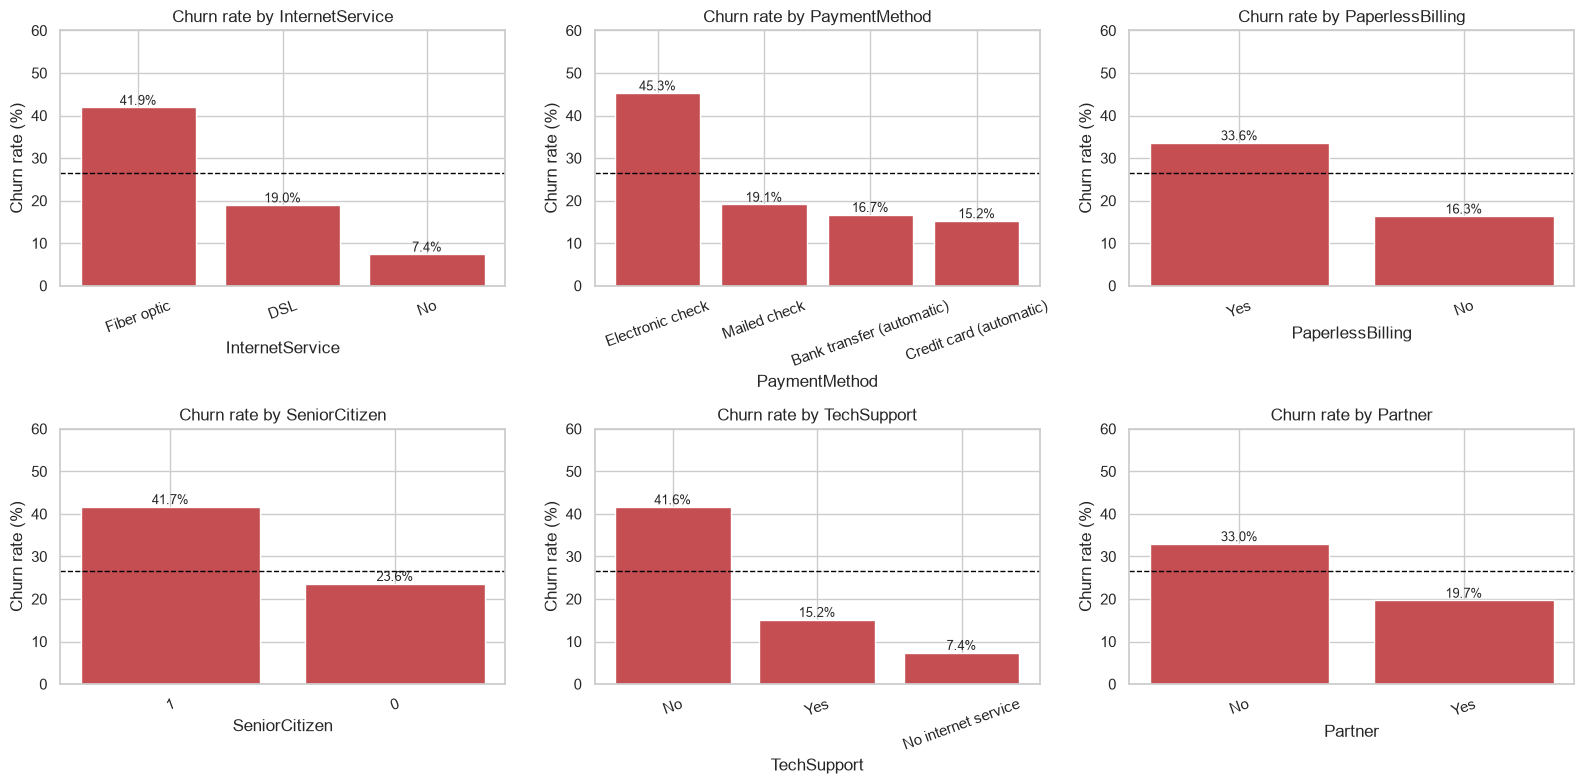

In [13]:
grid_cols = ['InternetService', 'PaymentMethod', 'PaperlessBilling',
             'SeniorCitizen', 'TechSupport', 'Partner']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), grid_cols):
    g = churn_rate(col)
    bars = ax.bar(g.index.astype(str), g['rate'], color='#C44E52')
    ax.bar_label(bars, fmt='%.1f%%', fontsize=9)
    ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1)
    ax.set_title(f'Churn rate by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Churn rate (%)')
    ax.set_ylim(0, 60)
    ax.tick_params(axis='x', rotation=20)
save_fig('03_churn_by_categoricals')
plt.show()

**Result:** fiber optic (41.9%), electronic check (45.3%), seniors (41.7%) and no tech support (41.6%) are well above the overall 26.5%.

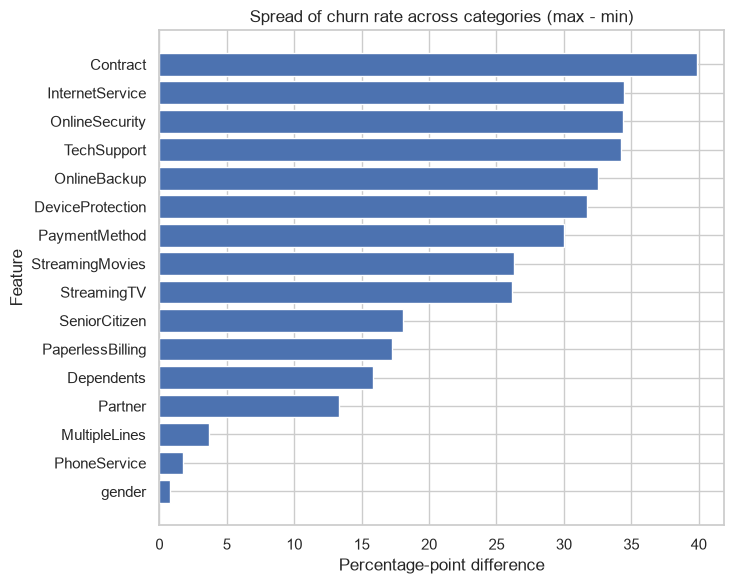

Contract            39.9
InternetService     34.5
OnlineSecurity      34.4
TechSupport         34.2
OnlineBackup        32.5
DeviceProtection    31.7
PaymentMethod       30.0
StreamingMovies     26.3
dtype: float64

In [14]:
spread = pd.Series({
    c: (lambda r: r.max() - r.min())(df.groupby(c)['Churn_flag'].mean())
    for c in cat_cols
}).mul(100).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 6))
ax.barh(spread.index, spread.values, color='#4C72B0')
ax.set_title('Spread of churn rate across categories (max - min)')
ax.set_xlabel('Percentage-point difference')
ax.set_ylabel('Feature')
save_fig('04_categorical_spread')
plt.show()

display(spread.sort_values(ascending=False).round(1).head(8))

**Result:** `Contract`, `InternetService`, `OnlineSecurity`, `TechSupport` separate churn most; `gender` almost not at all. This is single-feature only; features overlap.

## 5. Numeric features & outliers

In [15]:
display(df.groupby('Churn')[num_cols].agg(['mean', 'median', 'std']).round(1))

tenure              MonthlyCharges              TotalCharges          \
        mean median   std           mean median   std         mean  median   
Churn                                                                        
No      37.6   38.0  24.1           61.3   64.4  31.1       2549.9  1679.5   
Yes     18.0   10.0  19.5           74.4   79.6  24.7       1531.8   703.6   

               
          std  
Churn          
No     2330.0  
Yes    1890.8

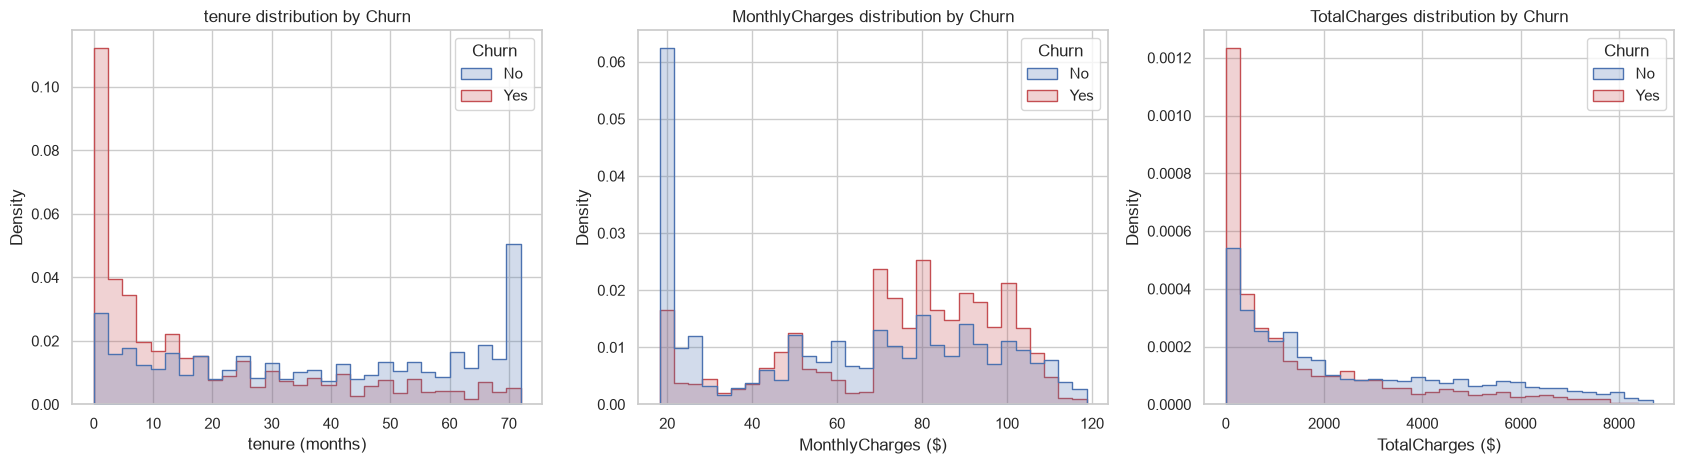

In [16]:
labels = {'tenure': 'tenure (months)',
          'MonthlyCharges': 'MonthlyCharges ($)',
          'TotalCharges': 'TotalCharges ($)'}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue='Churn', stat='density', common_norm=False,
                 element='step', bins=30, palette=PALETTE, ax=ax)
    ax.set_title(f'{col} distribution by Churn')
    ax.set_xlabel(labels[col])
    ax.set_ylabel('Density')
save_fig('05_numeric_distributions')
plt.show()

**Result:** churners have shorter tenure (median 10 vs 38 months), higher `MonthlyCharges` (74.4 vs 61.3), lower `TotalCharges`.

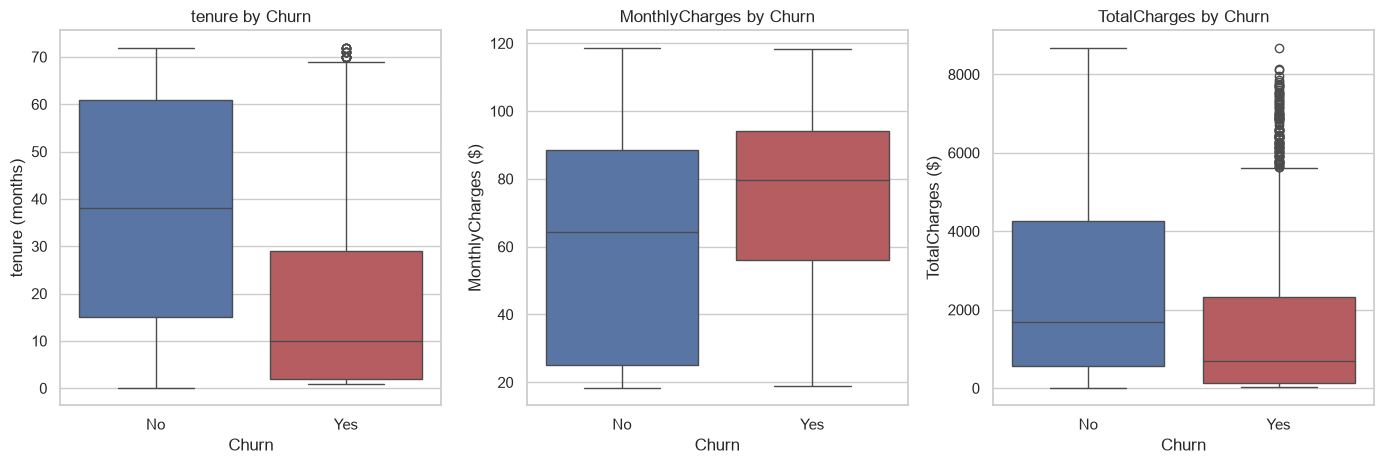

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x='Churn', y=col, hue='Churn', palette=PALETTE,
                legend=False, ax=ax)
    ax.set_title(f'{col} by Churn')
    ax.set_xlabel('Churn')
    ax.set_ylabel(labels[col])
save_fig('06_numeric_boxplots')
plt.show()

**Result:** `tenure` differs strongly between groups; `TotalCharges` is right-skewed.

In [18]:
def iqr_report(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    return pd.Series({'Q1': q1, 'Q3': q3, 'lower_fence': lo,
                      'upper_fence': hi, 'n_outliers': n_out,
                      'skew': s.skew()})


display(df[num_cols].apply(iqr_report).T.round(2))

,Q1,Q3,lower_fence,upper_fence,n_outliers,skew
tenure,9.00,55.00,-60.00,124.00,0.0,0.24
MonthlyCharges,35.50,89.85,-46.02,171.38,0.0,-0.22
TotalCharges,398.55,3786.60,-4683.52,8868.67,0.0,0.96


**Outliers:** none found with IQR; values are plausible. Nothing removed or capped.

## 6. Interactions & correlation

,rate,n
tenure_bin,,
0-6,52.9,1481
7-12,35.9,705
13-24,28.7,1024
25-48,20.4,1594
49-72,9.5,2239


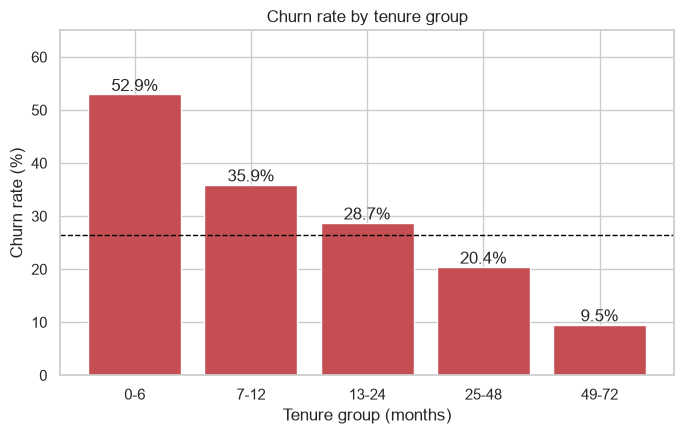

In [19]:
df['tenure_bin'] = pd.cut(df['tenure'], bins=[-1, 6, 12, 24, 48, 72],
                          labels=['0-6', '7-12', '13-24', '25-48', '49-72'])

g = churn_rate('tenure_bin').sort_index()
display(g.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(g.index.astype(str), g['rate'], color='#C44E52')
ax.bar_label(bars, fmt='%.1f%%')
ax.axhline(overall_rate, color='black', linestyle='--', linewidth=1)
ax.set_title('Churn rate by tenure group')
ax.set_xlabel('Tenure group (months)')
ax.set_ylabel('Churn rate (%)')
ax.set_ylim(0, 65)
save_fig('07_churn_by_tenure_bin')
plt.show()

**Result:** churn falls with tenure: 52.9% in the first 6 months, 9.5% after 4 years.

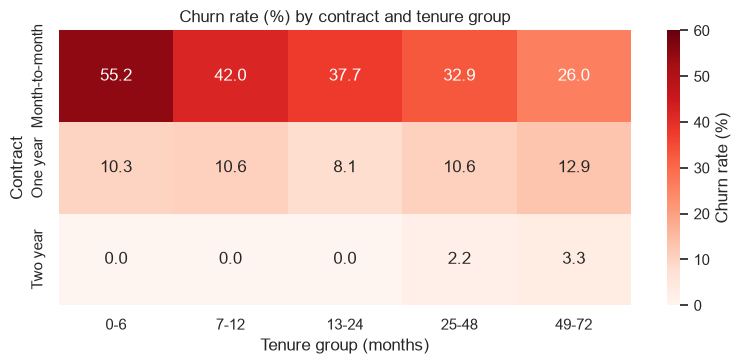

number of customers in each cell:


tenure_bin,0-6,7-12,13-24,25-48,49-72
Contract,,,,,
Month-to-month,1413,581,737,802,342
One year,39,85,197,518,634
Two year,29,39,90,274,1263


In [20]:
pt = df.pivot_table(index='Contract', columns='tenure_bin', values='Churn_flag',
                    aggfunc='mean', observed=True).mul(100)
pt_n = df.pivot_table(index='Contract', columns='tenure_bin', values='Churn_flag',
                      aggfunc='size', observed=True)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(pt, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=60,
            cbar_kws={'label': 'Churn rate (%)'}, ax=ax)
ax.set_title('Churn rate (%) by contract and tenure group')
ax.set_xlabel('Tenure group (months)')
ax.set_ylabel('Contract')
save_fig('08_contract_tenure_heatmap')
plt.show()

print('number of customers in each cell:')
display(pt_n)

**Result:** month-to-month is riskier than long contracts at every tenure group, so contract has its own effect. Small cells (see counts) are noisy.

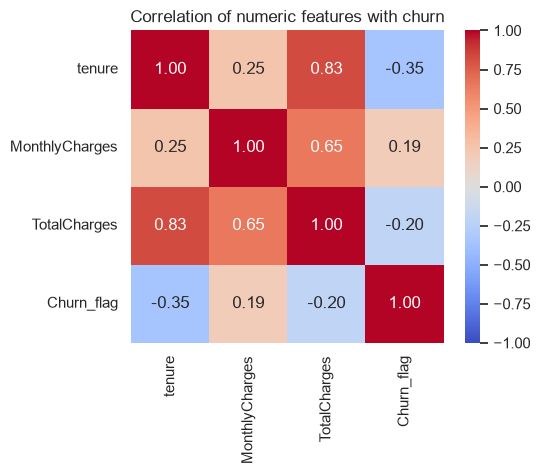

In [21]:
corr = df[num_cols + ['Churn_flag']].corr()

fig, ax = plt.subplots(figsize=(5.8, 4.8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            square=True, ax=ax)
ax.set_title('Correlation of numeric features with churn')
save_fig('09_numeric_correlation')
plt.show()

**Result:** `tenure` vs churn is -0.35, `MonthlyCharges` is 0.19, and `TotalCharges` vs `tenure` is 0.83 (collinearity for linear models). Correlation is not causation.

## 7. Key findings

- 26.5% churn; baseline accuracy ~73.5%.
- Contract: 42.7% / 11.3% / 2.8% (month-to-month / 1 year / 2 year).
- Internet: fiber 41.9%, DSL 19.0%, none 7.4%.
- Electronic check 45.3% vs ~15-19% for other payment methods.
- Tenure: 52.9% churn in first 6 months, 9.5% after 4 years.
- No tech support 41.6% vs 15.2%; seniors 41.7% vs 23.6%.
- `gender`: no effect (26.9% vs 26.2%).


## 8. Decisions for next steps

| Topic | Decision |
|---|---|
| `customerID` | drop |
| `TotalCharges` blank | `0` when `tenure == 0` (in `src/preprocess.py`) |
| Target | `Yes/No` -> `1/0` |
| Imbalance | `stratify=y`, F1/recall/PR-AUC, compare with/without `class_weight` |
| Categoricals | `OneHotEncoder(handle_unknown='ignore')` in `Pipeline` |
| Numerics | `StandardScaler` in `Pipeline` where needed |
| Collinearity | watch `TotalCharges` vs `tenure` in linear models |
| Feature ideas | `avg_monthly_charges`, number of services, `tenure_bin` |
| Outliers | none removed |